In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("insurance.csv")

In [2]:
print(df.head())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [3]:
df.shape

(1338, 7)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [6]:
print(df.describe())

               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


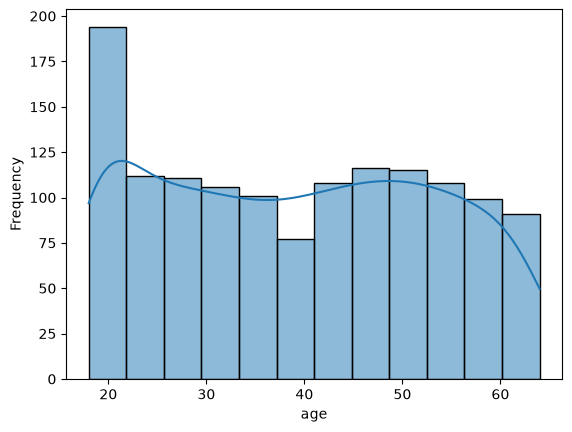

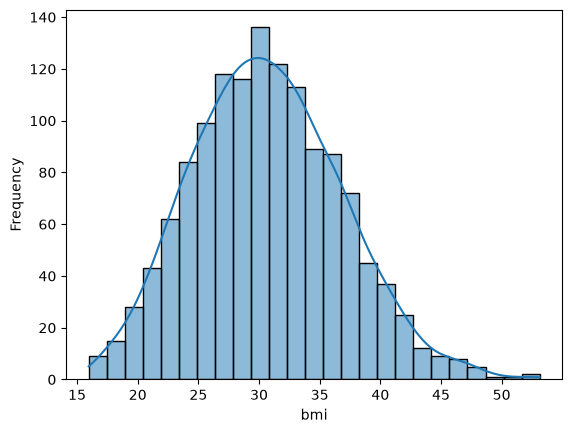

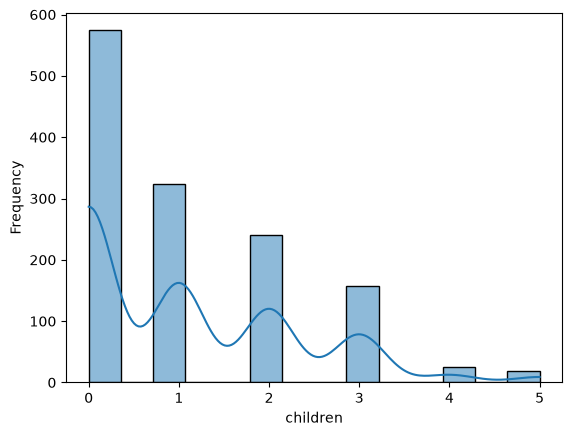

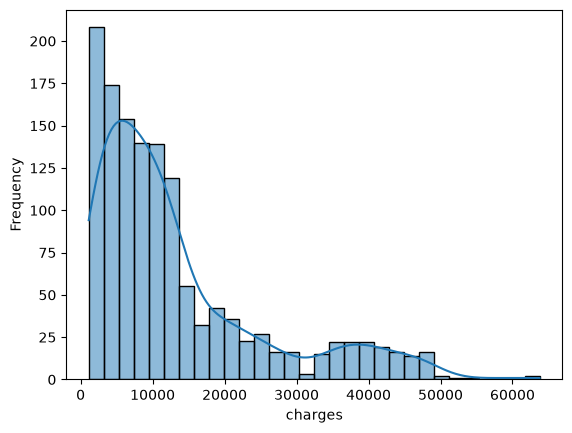

In [13]:
for col in ["age", "bmi", "children", "charges"]:##this loops for each column basically
    sns.histplot(data=df, x=col, kde=True)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

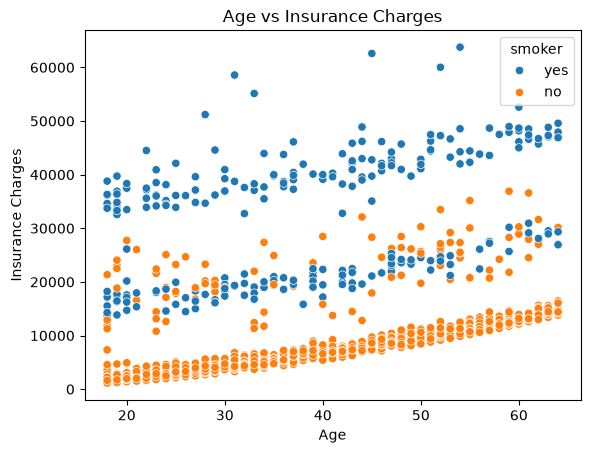

In [9]:
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")# hue basically sperates its not or it is 

plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.show()

In [17]:
# Select numerical columns
num = df[["age", "bmi", "children", "charges"]]

# Find minimum values of each column
minimum = num.min()

# Find maximum values of each column
maximum = num.max()

# Apply Min-Max normalization
df_norm = (num - minimum) / (maximum - minimum)

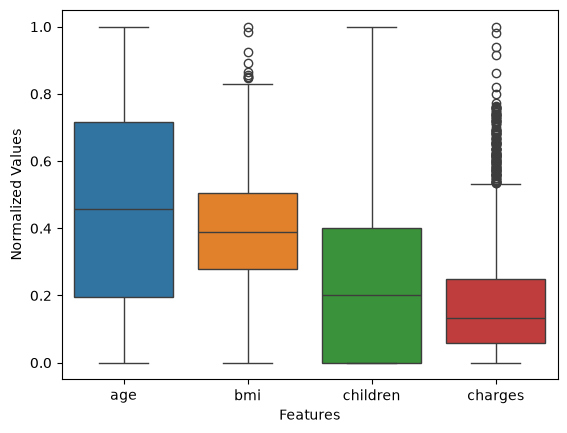

In [18]:
sns.boxplot(data=df_norm)
plt.xlabel("Features")
plt.ylabel("Normalized Values")
plt.show()

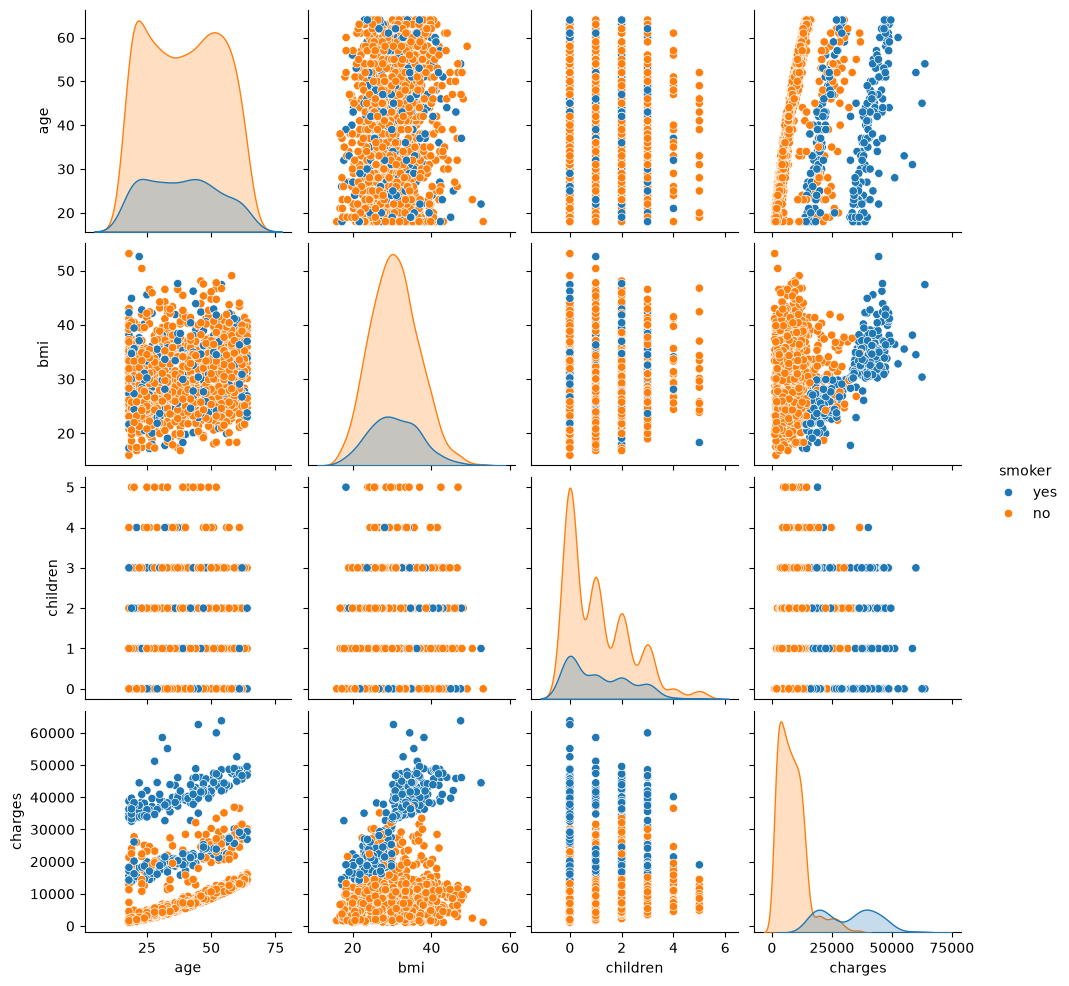

In [19]:
sns.pairplot(df, hue="smoker")
plt.show()

   age  sex     bmi  children  smoker  region      charges
0   19    1  27.900         0       1       0  16884.92400
1   18    0  33.770         1       0       1   1725.55230
2   28    0  33.000         3       0       1   4449.46200
3   33    0  22.705         0       0       2  21984.47061
4   32    0  28.880         0       0       2   3866.85520


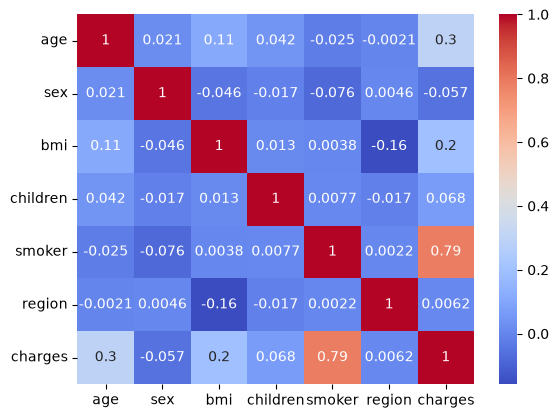

In [20]:
# Manual encoding

df["sex"] = df["sex"].map({
    "male": 0,
    "female": 1
})

df["smoker"] = df["smoker"].map({
    "no": 0,
    "yes": 1
})

df["region"] = df["region"].map({
    "southwest": 0,
    "southeast": 1,
    "northwest": 2,
    "northeast": 3
})

# Check encoded data
print(df.head())

# Correlation heatmap
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()